# 01 — Data audit

Audit of the cleaned UTS co-authorship dataset built by `linkpred.data.build`.
All tables come from `linkpred.data.audit`, which also writes them to `report/data_audit/`
and regenerates the numeric part of `docs/data_audit.md`. The audit is descriptive and uses
all years; nothing here is used as a model input.

In [1]:
import os, json
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
import pandas as pd
from IPython.display import Image, display
from linkpred.config import load_config
from linkpred.data import audit

pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:.3f}".format)
cfg = load_config()
res = audit.run(cfg)
log = json.loads(Path("report/data_audit/cleaning_log.json").read_text())

## Cleaning log
Every cleaning rule and how many rows it touched.

In [2]:
pd.Series(log).to_frame("value")

,value
source,/Users/zareenshyma/Documents/uts-research-inte...
raw_works,63514
raw_authorships,356586
duplicate_work_ids,0
missing_year_dropped,0
out_of_year_range_dropped,0
duplicate_doi,7
duplicate_title_year,1367
authorships_without_author_id_dropped,10848
works_affected_by_missing_author_id,4755


## Works, authors and new links per year

In [3]:
res["yearly"]

,year,works,works_over_cap,share_over_cap,share_with_abstract,authorships,active_authors,active_uts_authors,new_authors,edge_rows,distinct_pairs,new_pairs,new_pairs_uts_uts
0,2015,3399,12,0.004,0.638,14087,7872,2171,7872,32974,26304,26304,3713
1,2016,3967,13,0.003,0.648,17183,9652,2513,6910,44004,35893,30629,3506
2,2017,4439,23,0.005,0.671,20335,11625,2759,7665,50488,40674,32966,3377
3,2018,5387,36,0.007,0.640,25460,14276,3050,9229,64479,52317,41708,3894
4,2019,6256,45,0.007,0.617,30470,16592,3402,10006,81953,65150,50799,4826
5,2020,6709,79,0.012,0.657,37066,20357,3681,12383,106726,84648,66730,5526
6,2021,6842,83,0.012,0.658,38851,21334,3735,11984,113984,90308,67536,5266
7,2022,6305,88,0.014,0.679,38853,22046,3781,12458,121543,97341,73737,5680
8,2023,6332,69,0.011,0.677,38704,22243,3806,12409,121643,97206,74008,5947
9,2024,6193,70,0.011,0.735,38067,22775,3897,12667,118392,97483,73421,6075


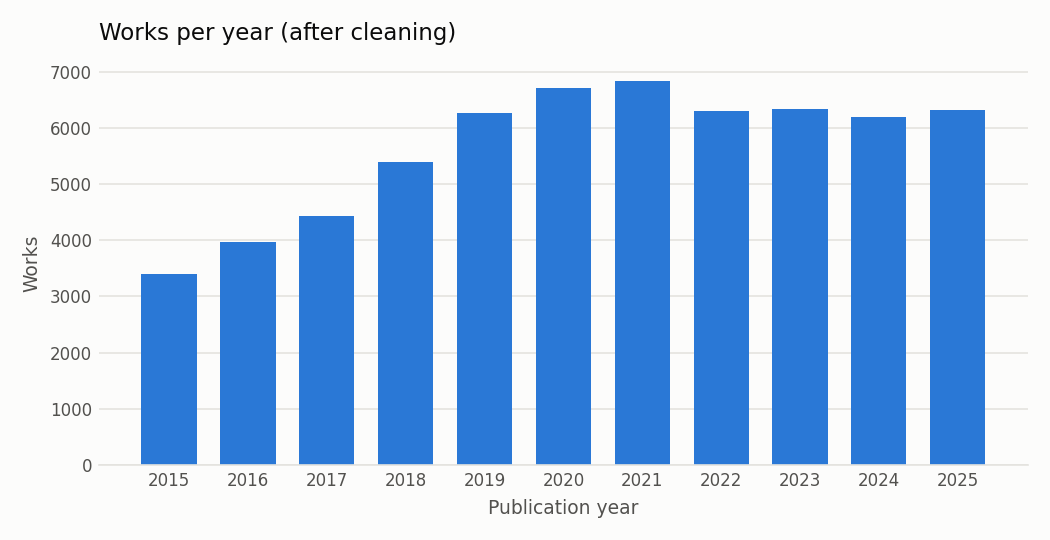

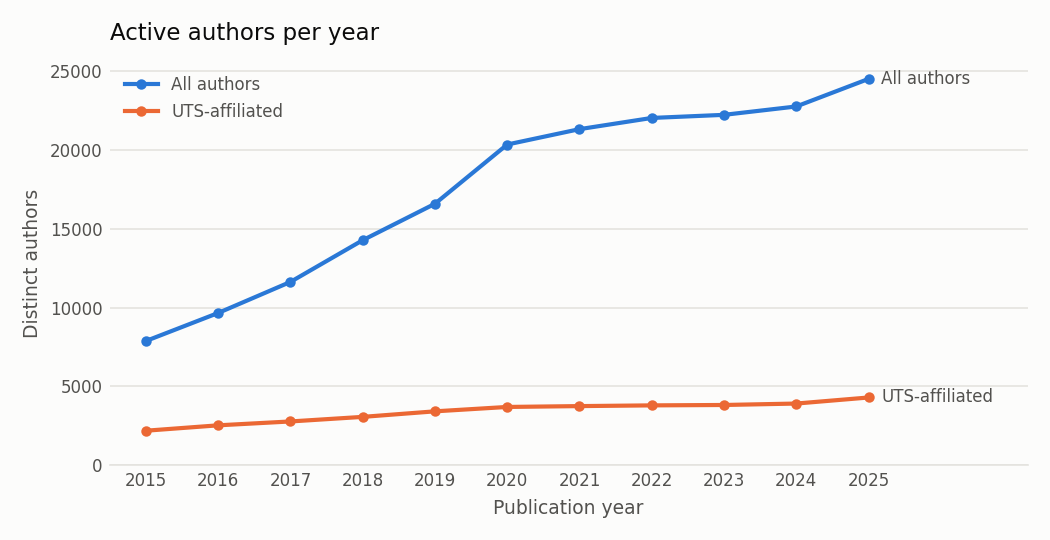

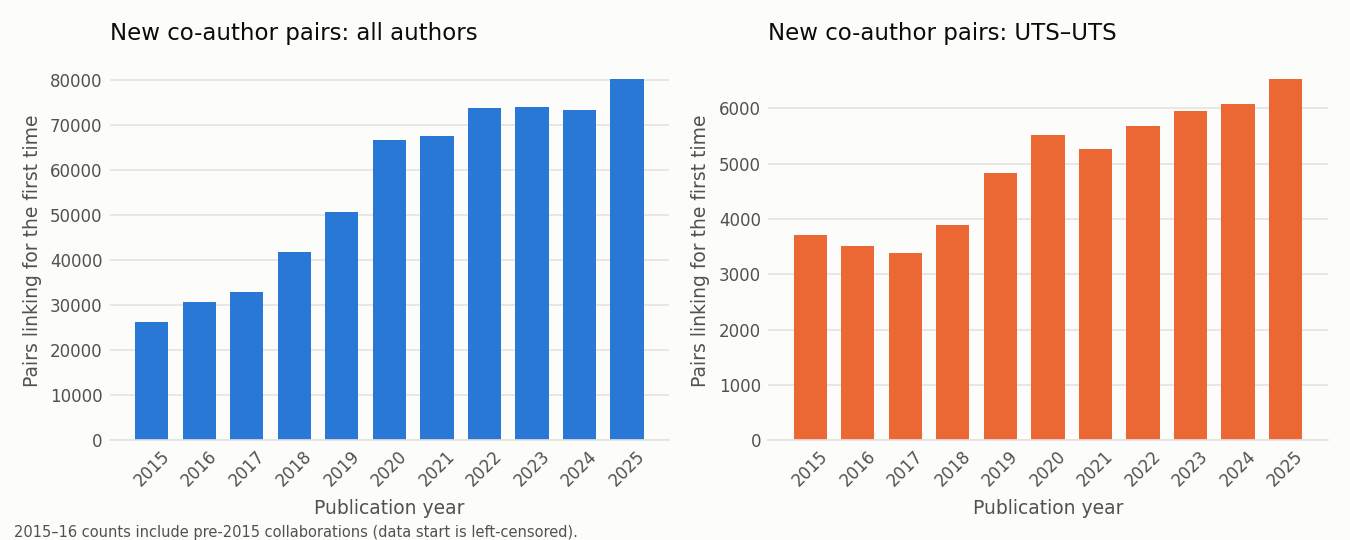

In [4]:
for f in ["audit_works_per_year.png", "audit_authors_per_year.png", "audit_new_edges_per_year.png"]:
    display(Image(f"figures/{f}"))

Note: 2015–2016 "new" pairs are inflated because the snapshot starts in 2015, so
collaborations that began earlier look new. This is one reason early years make poor label windows.

## Author cap
Works with more than `max_authors_per_work` authors are kept in `works.parquet` but produce no edges.

623 of 62140 works (1.00%) exceed 25 authors; 896,206 would-be edge rows not created (lower bound: API caps authorships at 100).


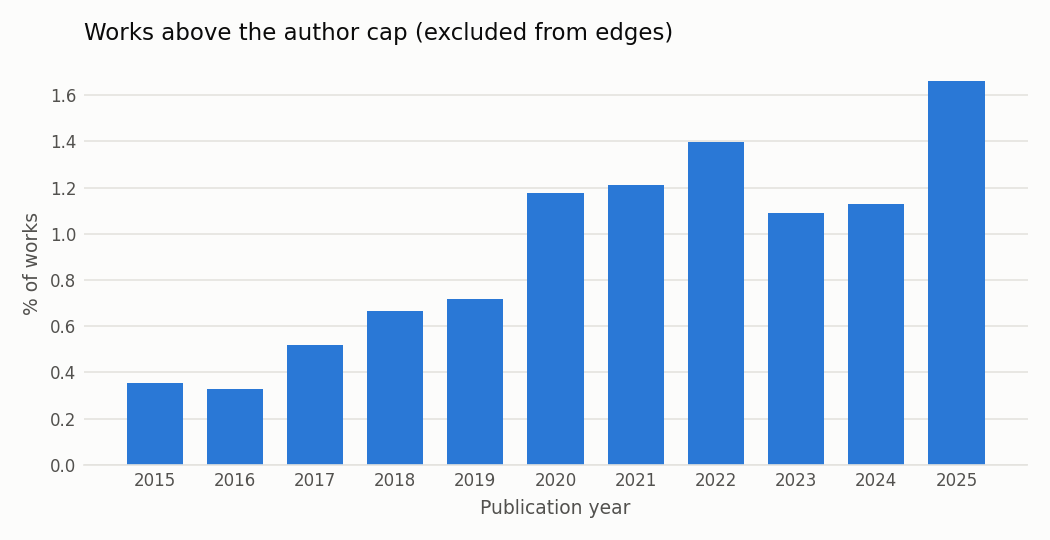

n_authors,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30
works,5577,6620,9168,10003,8634,6552,4232,2825,2116,1475,1012,740,586,424,323,271,220,174,103,116,106,78,64,49,49,53,38,22,17,493


In [5]:
w = pd.read_parquet("data/processed/works.parquet", columns=["work_id", "year", "n_authors", "type"])
cap = cfg["data"]["max_authors_per_work"]
print(f"{(w.n_authors > cap).sum()} of {len(w)} works ({(w.n_authors > cap).mean():.2%}) exceed {cap} authors; "
      f"{log['hyper_would_be_edges']:,} would-be edge rows not created (lower bound: API caps authorships at 100).")
display(Image("figures/audit_share_over_cap.png"))
w.n_authors.clip(upper=30).value_counts().sort_index().rename("works").to_frame().T

## Degree distribution (all years)

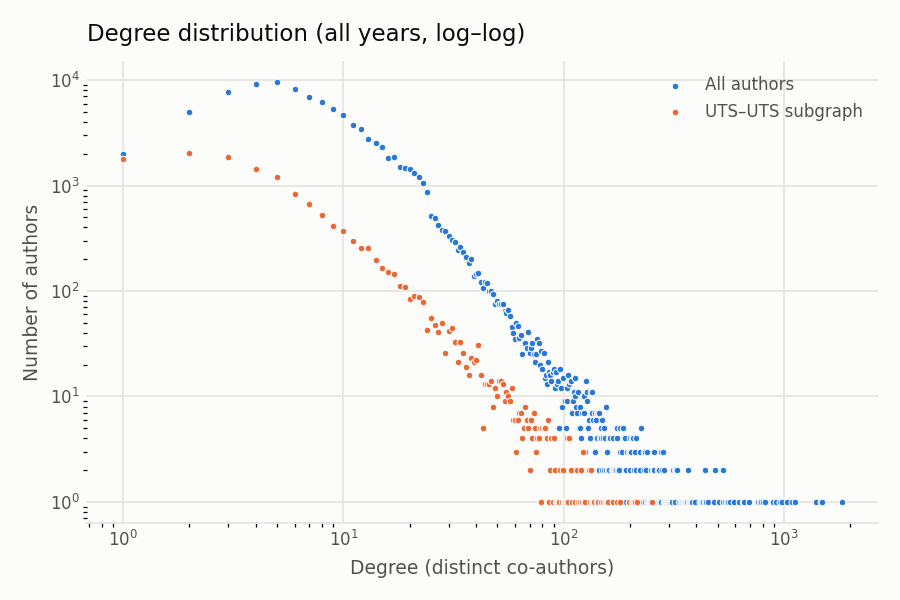

,nodes,edges,components,giant_component_share,mean_degree,median_degree,max_degree,density
all,100316.000,618015.000,1049.000,0.949,12.321,8.000,1825.000,0.000
uts_uts,14196.000,61801.000,341.000,0.930,8.707,4.000,252.000,0.001


In [6]:
display(Image("figures/audit_degree_loglog.png"))
pd.DataFrame(res["graph"]).T

Heavy-tailed, as expected for co-authorship. The highest-degree authors are prolific UTS
researchers; several carry a disambiguation flag, so some hubs may be merged profiles.

In [7]:
e = pd.read_parquet("data/processed/edges.parquet").drop_duplicates(["author_u", "author_v"])
a = pd.read_parquet("data/processed/authors.parquet").set_index("author_id")
deg = pd.concat([e.author_u, e.author_v]).value_counts().head(10).rename("degree")
a.loc[deg.index, ["n_works", "n_uts_works", "first_year", "last_year", "disambiguation_flag"]].join(deg)

,n_works,n_uts_works,first_year,last_year,disambiguation_flag,degree
A5040015789,760,753,2017,2025,True,1825
A5076048446,427,383,2015,2025,False,1493
A5056472365,651,638,2015,2025,True,1468
A5007273016,519,519,2015,2025,False,1392
A5035358791,427,256,2018,2025,True,1126
A5059040421,598,595,2017,2025,True,1084
A5005228053,525,524,2017,2025,True,1035
A5073251236,414,2,2017,2025,False,977
A5074742233,354,320,2015,2025,True,961
A5039341855,531,530,2018,2025,True,955


## Missingness

In [8]:
res["missingness"]

,level,field,n_missing,n_total,handling,share_missing
0,work,publication_year,0,63514,dropped,0.000
1,work,doi,2040,62140,kept; title+year dedup only,0.033
2,work,title (empty),56,62140,kept,0.001
3,work,abstract,20296,62140,kept; has_abstract=False,0.327
4,authorship,author_id,10848,348116,dropped,0.031
5,authorship,institution_ids (empty),12446,337268,kept,0.037
6,work,no UTS-affiliated identified author,1407,62140,kept,0.023


## Duplicates and disambiguation

In [9]:
flags = pd.read_parquet("data/processed/disambiguation_flags.parquet")
print("duplicates removed: DOI =", log["duplicate_doi"], "| title+year =", log["duplicate_title_year"])
print("disambiguation groups (all / UTS):", log["disambig_groups"], "/", log["disambig_groups_uts"])
print("author IDs involved (all / UTS):", log["disambig_author_ids"], "/", log["disambig_author_ids_uts"])
flags["n_ids"].value_counts().sort_index().rename("groups").to_frame().T

duplicates removed: DOI = 7 | title+year = 1367
disambiguation groups (all / UTS): 5719 / 1030
author IDs involved (all / UTS): 9228 / 2734


n_ids,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,26
groups,4556,633,289,83,43,22,11,8,4,1,9,3,4,46,3,1,1,1,1


## Work types
All types are kept for now (see open questions in `docs/data_audit.md`).

In [10]:
pd.read_csv("report/data_audit/work_types.csv").set_index("type").T

type,article,conference-paper,book-chapter,preprint,other,review,conference-abstract,reference-entry,editorial,book,dataset,erratum,paratext,book-review,peer-review,report,letter,data-paper,retraction,supplementary-materials,dissertation,software,software-paper
works,41617,7646,3587,2617,2151,1035,597,571,567,424,295,283,242,172,122,75,49,37,20,13,10,6,4


## Split candidates

For each cutoff `c` and window `[c, window_end]`: positives are pairs first co-authoring in the
window whose two authors are both already in the graph (edges with year < c). `pos_uts_uts` also
requires both to have had a UTS affiliation before `c`. This is the table the cutoff
recommendation in `docs/decisions.md` is based on.

In [11]:
res["candidates"]

,cutoff,window_end,window_years,graph_nodes,graph_edges_distinct,uts_nodes,new_pairs_in_window,pos_both_seen,pos_uts_uts,pos_uts_any_both_seen,share_both_seen
0,2017,2017,1,13443,56933,3275,32966,2990,1046,2252,0.091
1,2017,2018,2,13443,56933,3275,74674,5455,1944,4129,0.073
2,2017,2019,3,13443,56933,3275,125473,7322,2618,5573,0.058
3,2018,2018,1,20055,89899,4474,41708,4288,1406,3144,0.103
4,2018,2019,2,20055,89899,4474,92507,7666,2549,5670,0.083
5,2018,2020,3,20055,89899,4474,159237,10569,3427,7804,0.066
6,2019,2019,1,27978,131607,5700,50799,5960,1778,4273,0.117
7,2019,2020,2,27978,131607,5700,117529,11056,3261,7866,0.094
8,2019,2021,3,27978,131607,5700,185065,14998,4423,10682,0.081
9,2020,2020,1,36673,182406,6988,66730,8051,2201,5470,0.121


In [12]:
c = res["candidates"]
c[c.window_years == 1][["cutoff", "graph_nodes", "uts_nodes", "new_pairs_in_window", "pos_both_seen", "share_both_seen", "pos_uts_any_both_seen", "pos_uts_uts"]]

,cutoff,graph_nodes,uts_nodes,new_pairs_in_window,pos_both_seen,share_both_seen,pos_uts_any_both_seen,pos_uts_uts
0,2017,13443,3275,32966,2990,0.091,2252,1046
3,2018,20055,4474,41708,4288,0.103,3144,1406
6,2019,27978,5700,50799,5960,0.117,4273,1778
9,2020,36673,6988,66730,8051,0.121,5470,2201
12,2021,46978,8349,67536,9801,0.145,6133,2289
15,2022,57030,9625,73737,10495,0.142,6734,2367
18,2023,67446,10989,74008,10867,0.147,6491,2250
21,2024,78106,12415,73421,10894,0.148,6779,2229
23,2025,88741,13874,80177,11724,0.146,7238,2539
